# Phase 5: Sentiment Analysis Baseline
## TF-IDF + Logistic Regression Baseline Model

In this notebook, we establish a machine learning baseline for overall sentiment classification (`Negative`, `Neutral`, `Positive`).

Workflow:
1. Load processed review dataset
2. Train/Test Split (80/20 stratified)
3. Text vectorization using `TfidfVectorizer` (unigrams + bigrams)
4. Model training with `LogisticRegression`
5. Evaluate Accuracy, Precision, Recall, F1-Score, and Confusion Matrix
6. Save vectorizer and model artifacts to `app/models/trained_model/baseline/`

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

print("Baseline libraries loaded successfully!")

Baseline libraries loaded successfully!


In [2]:
data_path = "../data/processed/ecommerce_reviews.csv"
if not os.path.exists(data_path):
    data_path = "data/processed/ecommerce_reviews.csv"

df = pd.read_csv(data_path)
print(f"Loaded {len(df)} samples.")
print(df['sentiment'].value_counts())

Loaded 1500 samples.
sentiment
Negative    714
Positive    526
Neutral     260
Name: count, dtype: int64


In [3]:
# Stratified Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(
    df['review'],
    df['sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=df['sentiment']
)

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

Train size: 1200, Test size: 300


In [4]:
# TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Logistic Regression Classifier
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_tfidf, y_train)

# Evaluation
y_pred = model.predict(X_test_tfidf)
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

=== Classification Report ===
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       143
     Neutral       0.83      0.96      0.89        52
    Positive       0.98      0.90      0.94       105

    accuracy                           0.96       300
   macro avg       0.94      0.96      0.94       300
weighted avg       0.96      0.96      0.96       300



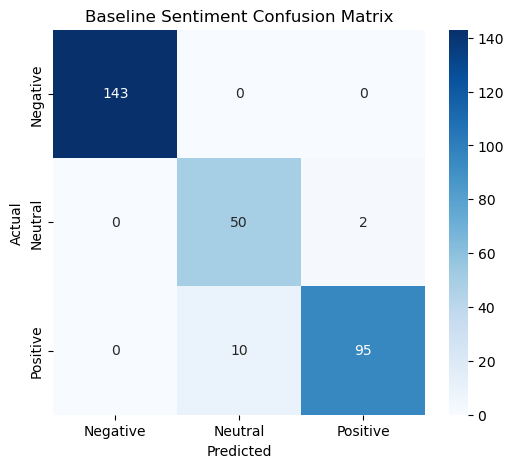

In [5]:
cm = confusion_matrix(y_test, y_pred, labels=['Negative', 'Neutral', 'Positive'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
plt.title('Baseline Sentiment Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [6]:
save_dir = "../app/models/trained_model/baseline"
os.makedirs(save_dir, exist_ok=True)

joblib.dump(vectorizer, os.path.join(save_dir, "tfidf_vectorizer.joblib"))
joblib.dump(model, os.path.join(save_dir, "baseline_model.joblib"))
print(f"Baseline model and vectorizer saved to {save_dir}")

Baseline model and vectorizer saved to ../app/models/trained_model/baseline
